# B0005 — benchmark protocol: ablation, then full Bayesian optimization

Same test as the published results: train on the cycles before a start point, then forecast the
whole remaining capacity curve from the model's own predictions, no true capacity fed back.
RMSE across the forecast, on the normalised SOH scale.

Start point **cycle 134** = 80% of 168 cycles, which is Tian's `SP = 80%`, the protocol behind
the best published result (CNN-BiLSTM-AM, 0.00481). Set `START = 80` for Gao's.

**Stage 1** — ablation, 5 architectures x 2 target formulations x 5 seeds, to establish the best
architecture on this test.
**Stage 2** — Bayesian optimization of that architecture over **30+ hyperparameters**.
**Stage 3** — benchmark table.

### What Stage 2 tunes

| Group | Hyperparameters |
|---|---|
| data | window length (5-40) |
| CNN | depth 1-4; per layer: filters, kernel, dropout, pooling on/off; activation; batch-norm; global pooling type |
| multi-scale CNN *(if it wins)* | which kernel set: (2,3,5) / (3,5,7) / (3,7,11) / (5,9,13) |
| attention *(if it wins)* | projection width 4-64, activation |
| LSTM | depth 1-3; per layer: units, dropout, recurrent dropout |
| dense head | depth 1-4; per layer: units, dropout; activation |
| regularisation | L2 strength, output activation |
| training | optimizer (4), learning rate (log-continuous), batch size, loss function, gradient clipping, LR-schedule factor and patience |

Keras Tuner only samples the hyperparameters that are active for a given depth, so the effective
dimensionality is well below the raw count — but it is still large. Two consequences worth
knowing rather than discovering later: Bayesian search behaves more like random search as
dimensionality grows, which is why `MAX_TRIALS` is 60 rather than 30; and with 92 training
windows a large space can fit the 31-window validation set rather than the problem, which is why
every trial is the mean of 3 seeds and the final figure is re-measured on 10 unseen seeds.

Run from the folder containing `B0005.mat`. Roughly 1.5-2.5 hours; Keras Tuner checkpoints each
trial, so an interrupted run resumes.

In [1]:
import os, json, gc, time
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
import numpy as np, pandas as pd
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, AveragePooling1D, Dropout,
                                     Dense, LSTM, Bidirectional, Concatenate, Softmax, Multiply,
                                     Lambda, BatchNormalization, Flatten,
                                     GlobalMaxPooling1D, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import keras_tuner as kt
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('op determinism unavailable:', e)
print('TF', tf.__version__, '| keras-tuner', kt.__version__,
      '| GPU', tf.config.list_physical_devices('GPU'))

TF 2.10.0 | keras-tuner 1.4.8 | GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
MAT_PATH   = 'B0005.mat'
START      = 134        # Tian SP=80%.  Use 80 for Gao.
ABL_WINDOW = 10         # fixed during the ablation; tuned in Stage 2
MAX_WINDOW = 40
SEEDS_ABL, SEEDS_TRIAL, SEEDS_FINAL = 5, 3, 10
MAX_TRIALS = 60         # raised from 30 because the search space is much larger
ABL_EPOCHS, ABL_PATIENCE       = 300, 30
SEARCH_EPOCHS, SEARCH_PATIENCE = 200, 25
FINAL_EPOCHS,  FINAL_PATIENCE  = 400, 40
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

from scipy.io import loadmat
mat = loadmat(MAT_PATH); cycles = mat['B0005'][0, 0]['cycle'][0]
rows, n = [], 0
for i in range(len(cycles)):
    r = cycles[i]
    if r['type'][0] != 'discharge': continue
    n += 1; rows.append(dict(cycle=n, capacity=float(r['data'][0][0]['Capacity'][0][0])))
HI = pd.DataFrame(rows); C0 = HI['capacity'].iloc[0]
HI['SOH'] = (HI['capacity']/C0).astype(np.float32)
S, CYC = HI['SOH'].values.astype(np.float32), HI['cycle'].values
TEST_START = int(np.where(CYC >= START)[0][0]); HORIZON = len(HI) - TEST_START
FLOOR = float(np.sqrt(mean_squared_error(S[TEST_START:], np.full(HORIZON, S[TEST_START-1]))))
print('cycles %d | C0 %.4f Ah | train < cycle %d | forecast %d cycles | trivial floor %.5f'
      % (len(HI), C0, START, HORIZON, FLOOR))

_CACHE = {}
def get_data(window, target):
    k = (window, target)
    if k in _CACHE: return _CACHE[k]
    X, y = [], []
    for e in range(window, TEST_START):
        X.append(S[e-window:e].reshape(window, 1))
        y.append(S[e]-S[e-1] if target == 'delta' else S[e])
    X, y = np.asarray(X, np.float32), np.asarray(y, np.float32)
    cut = int(0.75*len(X))
    _CACHE[k] = dict(Xf=X[:cut], yf=y[:cut], Xv=X[cut:], yv=y[cut:],
                     val_start=window+cut, window=window)
    return _CACHE[k]

d = get_data(ABL_WINDOW, 'delta')
print('ablation split: fit %s | val %s' % (d['Xf'].shape, d['Xv'].shape))

cycles 168 | C0 1.8565 Ah | train < cycle 134 | forecast 35 cycles | trivial floor 0.02927
ablation split: fit (92, 10, 1) | val (31, 10, 1)


In [3]:
GI = lambda s: tf.keras.initializers.GlorotUniform(seed=s)

def attention_pool(seq, s, reg, units=16, act='tanh'):
    """Additive attention with a tunable projection width."""
    h = Dense(units, activation=act, kernel_initializer=GI(s), kernel_regularizer=reg)(seq)
    w = Softmax(axis=1)(Dense(1, kernel_initializer=GI(s), kernel_regularizer=reg)(h))
    return Lambda(lambda x: K.sum(x, axis=1))(Multiply()([seq, w]))

def make_model(window, bidirectional=False, attention=False, multiscale=False,
               n_cnn=1, cnn_filters=(32,), cnn_kernels=(3,), cnn_drops=(0.1,), cnn_pool=(True,),
               ms_kernels=(3, 5, 7), attn_units=16, attn_act='tanh',
               cnn_act='relu', batchnorm=False, global_pool='avg',
               n_lstm=1, lstm_units=(32,), lstm_drops=(0.0,), lstm_rdrops=(0.0,),
               n_dense=1, dense_units=(64,), dense_drops=(0.1,), dense_act='relu',
               l2=0.0, out_act='linear',
               optimizer='adam', lr=1e-3, loss='mse', clipnorm=0.0, seed=SEED):
    reg = regularizers.l2(l2) if l2 and l2 > 0 else None
    kw  = dict(kernel_initializer=GI(seed), kernel_regularizer=reg)
    inp = Input(shape=(window, 1))
    # ---------------- CNN branch ----------------
    c = inp
    for i in range(n_cnn):
        if multiscale:
            c = Concatenate()([Conv1D(cnn_filters[i], k, padding='same', **kw)(c)
                               for k in ms_kernels])
        else:
            c = Conv1D(cnn_filters[i], cnn_kernels[i], padding='same', **kw)(c)
        if batchnorm: c = BatchNormalization()(c)
        c = tf.keras.layers.Activation(cnn_act)(c)
        c = Dropout(cnn_drops[i], seed=seed)(c)
        if cnn_pool[i] and int(c.shape[1]) > 2:
            c = MaxPooling1D(2, padding='same')(c)
    c = {'max': GlobalMaxPooling1D(), 'avg': GlobalAveragePooling1D(),
         'flatten': Flatten()}[global_pool](c)
    # ---------------- LSTM branch ----------------
    r = inp
    for i in range(n_lstm):
        last = (i == n_lstm-1)
        cell = LSTM(lstm_units[i], return_sequences=(not last) or attention,
                    dropout=lstm_drops[i], recurrent_dropout=lstm_rdrops[i], **kw)
        r = Bidirectional(cell)(r) if bidirectional else cell(r)
    if attention: r = attention_pool(r, seed, reg, attn_units, attn_act)
    # ---------------- head ----------------
    h = Concatenate()([c, r])
    for i in range(n_dense):
        h = Dense(dense_units[i], activation=dense_act, **kw)(h)
        h = Dropout(dense_drops[i], seed=seed)(h)
    out = Dense(1, activation=out_act, **kw)(h)
    okw = dict(clipnorm=clipnorm) if clipnorm and clipnorm > 0 else {}
    opt = {'adam': tf.keras.optimizers.Adam, 'rmsprop': tf.keras.optimizers.RMSprop,
           'sgd': tf.keras.optimizers.SGD, 'nadam': tf.keras.optimizers.Nadam
           }[optimizer](learning_rate=lr, **okw)
    lss = {'mse': 'mse', 'mae': 'mae', 'huber': tf.keras.losses.Huber()}[loss]
    m = Model(inp, out); m.compile(optimizer=opt, loss=lss, metrics=['mae']); return m

def train(m, d, ep, pat, batch=16, lr_factor=0.5, lr_patience=8):
    m.fit(d['Xf'], d['yf'], validation_data=(d['Xv'], d['yv']), epochs=ep, batch_size=batch,
          verbose=0, shuffle=True,
          callbacks=[EarlyStopping('val_loss', patience=pat, restore_best_weights=True),
                     ReduceLROnPlateau('val_loss', factor=lr_factor, patience=lr_patience,
                                       min_lr=1e-7)])
    return m

def forecast(m, target, window, start_idx, n):
    win, out, prev = list(S[start_idx-window:start_idx]), [], float(S[start_idx-1])
    for _ in range(n):
        x = np.asarray(win[-window:], np.float32).reshape(1, window, 1)
        p = float(m(x, training=False).numpy().ravel()[0])
        lvl = float(np.clip(prev + p if target == 'delta' else p, 0.0, 1.2))
        out.append(lvl); win.append(lvl); prev = lvl
    return np.asarray(out, np.float32)

def rmse_forecast(m, target, window, part='test'):
    if part == 'test': st, n = TEST_START, HORIZON
    else:
        d = get_data(window, target); st, n = d['val_start'], len(d['Xv'])
    return float(np.sqrt(mean_squared_error(S[st:st+n], forecast(m, target, window, st, n))))

## Stage 1 — ablation on the benchmark protocol

Selection is on the **validation** forecast, never the test forecast.

In [4]:
LADDER = [
    ('R0', 'CNN-LSTM (plain)',     dict(bidirectional=False, attention=False, multiscale=False)),
    ('R1', '+ bidirectional',      dict(bidirectional=True,  attention=False, multiscale=False)),
    ('R2', '+ attention pooling',  dict(bidirectional=True,  attention=True,  multiscale=False)),
    ('R3', '+ multi-scale CNN',    dict(bidirectional=True,  attention=True,  multiscale=True)),
    ('R4', 'multi-scale, no attn', dict(bidirectional=True,  attention=False, multiscale=True)),
]
abl, t0 = [], time.time()
for target in ('delta', 'level'):
    d = get_data(ABL_WINDOW, target)
    for rid, label, flags in LADDER:
        vs, ts = [], []
        for s in range(SEEDS_ABL):
            K.clear_session(); gc.collect()
            np.random.seed(SEED+s); tf.random.set_seed(SEED+s)
            m = make_model(ABL_WINDOW, seed=SEED+s, **flags)
            train(m, d, ABL_EPOCHS, ABL_PATIENCE)
            vs.append(rmse_forecast(m, target, ABL_WINDOW, 'val'))
            ts.append(rmse_forecast(m, target, ABL_WINDOW, 'test'))
        abl.append(dict(id=rid, config=label, target=target, **flags,
                        val_mean=float(np.mean(vs)), val_std=float(np.std(vs, ddof=1)),
                        test_mean=float(np.mean(ts)), test_std=float(np.std(ts, ddof=1)),
                        test_best=float(np.min(ts))))
        print('%-3s %-22s %-6s val %.5f +/- %.5f | test %.5f +/- %.5f'
              % (rid, label, target, np.mean(vs), np.std(vs, ddof=1),
                 np.mean(ts), np.std(ts, ddof=1)))
print('\nablation done in %.0f s' % (time.time()-t0))

A = pd.DataFrame(abl).sort_values('val_mean').reset_index(drop=True)
pd.set_option('display.width', 200)
print('\nranked by validation forecast\n')
print(A[['id','config','target','val_mean','val_std','test_mean','test_std']].to_string(index=False))
WIN = A.iloc[0]
print('\nWINNER: %s %s (%s target)' % (WIN['id'], WIN['config'], WIN['target']))
A.to_csv('recursive_ablation_b0005_start%d.csv' % START, index=False)

R0  CNN-LSTM (plain)       delta  val 0.05055 +/- 0.05717 | test 0.10760 +/- 0.11187
R1  + bidirectional        delta  val 0.04910 +/- 0.05868 | test 0.05744 +/- 0.04207
R2  + attention pooling    delta  val 0.03626 +/- 0.03403 | test 0.08866 +/- 0.09357
R3  + multi-scale CNN      delta  val 0.01745 +/- 0.02364 | test 0.01538 +/- 0.00929
R4  multi-scale, no attn   delta  val 0.00848 +/- 0.00347 | test 0.01053 +/- 0.00412
R0  CNN-LSTM (plain)       level  val 0.01738 +/- 0.01328 | test 0.02476 +/- 0.02778
R1  + bidirectional        level  val 0.01426 +/- 0.01003 | test 0.01299 +/- 0.00445
R2  + attention pooling    level  val 0.01793 +/- 0.01140 | test 0.01177 +/- 0.00655
R3  + multi-scale CNN      level  val 0.02869 +/- 0.01530 | test 0.03344 +/- 0.01553
R4  multi-scale, no attn   level  val 0.01203 +/- 0.00701 | test 0.01546 +/- 0.01077

ablation done in 585 s

ranked by validation forecast

id               config target  val_mean  val_std  test_mean  test_std
R4 multi-scale, no attn

## Stage 2 — full Bayesian optimization of the winning architecture

Everything except the three architecture switches is now searched.

In [5]:
BEST_FLAGS = dict(bidirectional=bool(WIN['bidirectional']), attention=bool(WIN['attention']),
                  multiscale=bool(WIN['multiscale']))
BEST_TARGET = WIN['target']
OBJ = 'val_forecast_rmse'

def hp_config(hp):
    """Every tunable in one place, so the trial record is self-documenting."""
    n_cnn   = hp.Int('n_cnn', 1, 4)
    n_lstm  = hp.Int('n_lstm', 1, 3)
    n_dense = hp.Int('n_dense', 1, 4)
    cfg = dict(
        window      = hp.Int('window', 5, MAX_WINDOW, step=5),
        n_cnn       = n_cnn,
        cnn_filters = [hp.Int('cnn_%d_filters' % i, 8, 160, step=8) for i in range(n_cnn)],
        cnn_drops   = [hp.Float('cnn_%d_drop'  % i, 0.0, 0.5, step=0.05) for i in range(n_cnn)],
        cnn_pool    = [hp.Boolean('cnn_%d_pool' % i)                for i in range(n_cnn)],
        cnn_act     = hp.Choice('cnn_act', ['relu', 'elu', 'tanh', 'swish']),
        batchnorm   = hp.Boolean('batchnorm'),
        global_pool = hp.Choice('global_pool', ['avg', 'max', 'flatten']),
        n_lstm      = n_lstm,
        lstm_units  = [hp.Int('lstm_%d_units' % i, 8, 160, step=8)  for i in range(n_lstm)],
        lstm_drops  = [hp.Float('lstm_%d_drop' % i, 0.0, 0.5, step=0.05) for i in range(n_lstm)],
        lstm_rdrops = [hp.Float('lstm_%d_rdrop'% i, 0.0, 0.5, step=0.05) for i in range(n_lstm)],
        n_dense     = n_dense,
        dense_units = [hp.Int('dense_%d_units' % i, 8, 320, step=8) for i in range(n_dense)],
        dense_drops = [hp.Float('dense_%d_drop'% i, 0.0, 0.6, step=0.05) for i in range(n_dense)],
        dense_act   = hp.Choice('dense_act', ['relu', 'elu', 'tanh', 'swish']),
        l2          = hp.Float('l2', 1e-7, 1e-2, sampling='log'),
        out_act     = (hp.Choice('out_act', ['linear', 'sigmoid'])
                       if BEST_TARGET == 'level' else 'linear'),
        optimizer   = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd', 'nadam']),
        lr          = hp.Float('lr', 1e-5, 1e-2, sampling='log'),
        loss        = hp.Choice('loss', ['mse', 'mae', 'huber']),
        clipnorm    = hp.Choice('clipnorm', [0.0, 0.5, 1.0, 5.0]),
    )
    # kernel size only means something when the CNN is single-scale; when it is
    # multi-scale the *set* of kernels is what matters, so that is searched instead.
    if BEST_FLAGS['multiscale']:
        cfg['ms_kernels'] = tuple(int(v) for v in hp.Choice(
            'ms_kernel_set', ['2,3,5', '3,5,7', '3,7,11', '5,9,13']).split(','))
        cfg['cnn_kernels'] = [3] * n_cnn                 # unused by the multi-scale branch
    else:
        cfg['cnn_kernels'] = [hp.Int('cnn_%d_kernel' % i, 2, 9) for i in range(n_cnn)]
    # attention gets its own width and activation whenever it is in use
    if BEST_FLAGS['attention']:
        cfg['attn_units'] = hp.Int('attn_units', 4, 64, step=4)
        cfg['attn_act']   = hp.Choice('attn_act', ['tanh', 'relu'])
    train_cfg = dict(batch      = hp.Choice('batch_size', [8, 16, 32, 64]),
                     lr_factor  = hp.Choice('lr_factor', [0.2, 0.5, 0.8]),
                     lr_patience= hp.Int('lr_patience', 3, 15))
    return cfg, train_cfg

def build_only(hp, seed=SEED):
    """Build without training — Keras Tuner needs a hypermodel it can call cheaply."""
    cfg, _ = hp_config(hp)
    w = cfg.pop('window')
    return make_model(w, seed=seed, **BEST_FLAGS, **cfg)

def build_and_train(hp, seed, epochs, patience):
    cfg, tcfg = hp_config(hp)
    w = cfg.pop('window')
    d = get_data(w, BEST_TARGET)
    m = make_model(w, seed=seed, **BEST_FLAGS, **cfg)
    train(m, d, epochs, patience, **tcfg)
    return m, w

# how large is the space actually being searched?
_probe = kt.HyperParameters(); build_only(_probe)
print('hyperparameters registered on one sampled configuration: %d' % len(_probe.values))

class MultiSeedBO(kt.BayesianOptimization):
    def run_trial(self, trial, *a, **kw):
        hp, sc = trial.hyperparameters, []
        for s in range(SEEDS_TRIAL):
            K.clear_session(); gc.collect()
            np.random.seed(SEED+s); tf.random.set_seed(SEED+s)
            try:
                m, w = build_and_train(hp, SEED+s, SEARCH_EPOCHS, SEARCH_PATIENCE)
                v = rmse_forecast(m, BEST_TARGET, w, 'val')
                if not np.isfinite(v): v = 1e3
            except Exception as e:
                print('   seed %d failed (%s: %s)' % (s, type(e).__name__, str(e)[:60])); v = 1e3
            sc.append(v)
        print('   trial %s: %.5f (std %.5f)' % (trial.trial_id, np.mean(sc), np.std(sc, ddof=1)))
        return {OBJ: float(np.mean(sc))}

t0 = time.time()
tuner = MultiSeedBO(hypermodel=build_only,
                    objective=kt.Objective(OBJ, direction='min'),
                    max_trials=MAX_TRIALS, seed=SEED,
                    directory='bo_full_b0005', project_name='start%d' % START, overwrite=False)
tuner.search()
best_hp = tuner.get_best_hyperparameters(1)[0]
print('\nsearch done in %.0f s (%d trials)' % (time.time()-t0, len(tuner.oracle.trials)))

Trial 60 Complete [01h 13m 23s]
val_forecast_rmse: 0.012542930742104849

Best val_forecast_rmse So Far: 0.0058244952621559305
Total elapsed time: 23h 42m 44s

search done in 85365 s (60 trials)


In [6]:
scores, params, wsel = [], None, None
for s in range(SEEDS_FINAL):
    K.clear_session(); gc.collect()
    sd = SEED+1000+s; np.random.seed(sd); tf.random.set_seed(sd)
    m, wsel = build_and_train(best_hp, sd, FINAL_EPOCHS, FINAL_PATIENCE)
    params = m.count_params()
    scores.append(rmse_forecast(m, BEST_TARGET, wsel, 'test'))

TUNED = dict(mean=float(np.mean(scores)), std=float(np.std(scores, ddof=1)),
             best=float(np.min(scores)), params=int(params), window=int(wsel),
             per_seed=[round(v, 5) for v in scores], hp=dict(best_hp.values),
             flags=BEST_FLAGS, target=BEST_TARGET, start=START, floor=FLOOR,
             n_hyperparams=len(best_hp.values))
print('=' * 72)
print('architecture  : %s (%s target)' % (WIN['config'], BEST_TARGET))
print('BEFORE tuning : %.5f +/- %.5f' % (WIN['test_mean'], WIN['test_std']))
print('AFTER  tuning : %.5f +/- %.5f   (best seed %.5f)'
      % (TUNED['mean'], TUNED['std'], TUNED['best']))
print('trivial floor : %.5f | params %s | %d hyperparameters tuned'
      % (FLOOR, format(params, ','), TUNED['n_hyperparams']))
print('=' * 72)
for k, v in sorted(TUNED['hp'].items()): print('   %-18s %s' % (k, v))

architecture  : multi-scale, no attn (delta target)
BEFORE tuning : 0.01053 +/- 0.00412
AFTER  tuning : 0.01063 +/- 0.00159   (best seed 0.00860)
trivial floor : 0.02927 | params 1,057,609 | 46 hyperparameters tuned
   batch_size         8
   batchnorm          True
   clipnorm           5.0
   cnn_0_drop         0.45
   cnn_0_filters      96
   cnn_0_pool         False
   cnn_1_drop         0.35000000000000003
   cnn_1_filters      40
   cnn_1_pool         True
   cnn_2_drop         0.1
   cnn_2_filters      128
   cnn_2_pool         False
   cnn_3_drop         0.2
   cnn_3_filters      24
   cnn_3_pool         True
   cnn_act            relu
   dense_0_drop       0.05
   dense_0_units      168
   dense_1_drop       0.05
   dense_1_units      112
   dense_2_drop       0.30000000000000004
   dense_2_units      232
   dense_3_drop       0.2
   dense_3_units      152
   dense_act          swish
   global_pool        avg
   l2                 4.2801480880363266e-05
   loss               m

## Stage 3 — benchmark table

B0005 — recursive forecast from cycle 134, RMSE on SOH

                                                    method     source  rmse_SOH
1                                            CNN-BiLSTM-AM  Tian 2022   0.00481
2                                               CNN-BiLSTM  Tian 2022   0.00595
3                                                   BiLSTM  Tian 2022   0.00620
4                                            1D CNN-BiLSTM   Gao 2023   0.00772
5                                                      CNN  Tian 2022   0.00863
6                                                   1D CNN   Gao 2023   0.00866
7                                              1D CNN-LSTM   Gao 2023   0.00932
8                      Ours: multi-scale, no attn, untuned  this work   0.01053
9   Ours: multi-scale, no attn + Bayesian (46 hyperparams)  this work   0.01063
10                                              1D CNN-RNN   Gao 2023   0.01661
11                                                     RNN   Gao

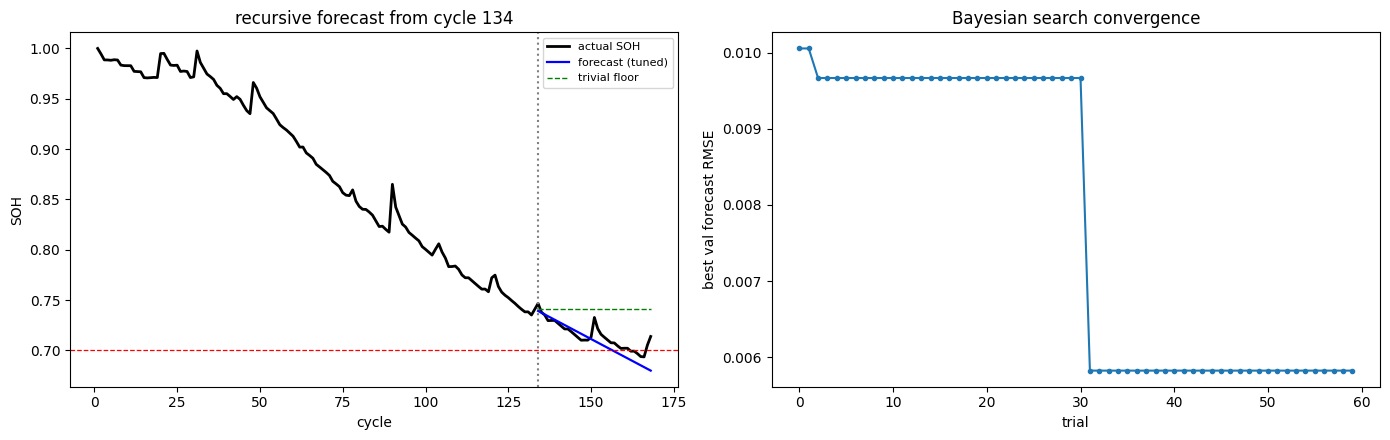


saved benchmark and results files


In [7]:
PUB = [('CNN-BiLSTM-AM','Tian 2022',0.00481),('CNN-BiLSTM','Tian 2022',0.00595),
       ('BiLSTM','Tian 2022',0.00620),('1D CNN-BiLSTM','Gao 2023',0.00772),
       ('CNN','Tian 2022',0.00863),('1D CNN','Gao 2023',0.00866),
       ('1D CNN-LSTM','Gao 2023',0.00932),('1D CNN-RNN','Gao 2023',0.01661),
       ('RNN','Gao 2023',0.01776),('BiLSTM','Gao 2023',0.01986),('LSTM','Gao 2023',0.02302)]
rows  = [dict(method=m, source=s, rmse_SOH=v) for m, s, v in PUB]
rows += [dict(method='Ours: %s + Bayesian (%d hyperparams)' % (WIN['config'], TUNED['n_hyperparams']),
              source='this work', rmse_SOH=round(TUNED['mean'], 5)),
         dict(method='Ours: %s, untuned' % WIN['config'], source='this work',
              rmse_SOH=round(float(WIN['test_mean']), 5)),
         dict(method='   trivial floor (flat line)', source='reference', rmse_SOH=round(FLOOR, 5))]
B = pd.DataFrame(rows).sort_values('rmse_SOH').reset_index(drop=True); B.index = B.index+1
print('B0005 — recursive forecast from cycle %d, RMSE on SOH\n' % START)
print(B.to_string())
B.to_csv('benchmark_b0005_recursive_start%d.csv' % START)
json.dump(dict(start=START, horizon=HORIZON, floor=FLOOR, ablation=abl, tuned=TUNED),
          open('recursive_bo_b0005_start%d.json' % START, 'w'), indent=2, default=str)

import matplotlib.pyplot as plt
K.clear_session(); np.random.seed(SEED); tf.random.set_seed(SEED)
m, w = build_and_train(best_hp, SEED, FINAL_EPOCHS, FINAL_PATIENCE)
pred = forecast(m, BEST_TARGET, w, TEST_START, HORIZON)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(CYC, S, 'k-', lw=2, label='actual SOH')
ax[0].plot(CYC[TEST_START:], pred, 'b-', lw=1.6, label='forecast (tuned)')
ax[0].plot(CYC[TEST_START:], np.full(HORIZON, S[TEST_START-1]), 'g--', lw=1, label='trivial floor')
ax[0].axvline(START, color='grey', ls=':'); ax[0].axhline(0.70, color='r', ls='--', lw=.9)
ax[0].set_xlabel('cycle'); ax[0].set_ylabel('SOH'); ax[0].legend(fontsize=8)
ax[0].set_title('recursive forecast from cycle %d' % START)
vals = [t.score for t in tuner.oracle.trials.values()
        if t.score is not None and np.isfinite(t.score) and t.score < 1e2]
ax[1].plot(np.minimum.accumulate(vals), marker='o', ms=3)
ax[1].set_xlabel('trial'); ax[1].set_ylabel('best val forecast RMSE')
ax[1].set_title('Bayesian search convergence')
plt.tight_layout(); plt.show()
print('\nsaved benchmark and results files')